# Phase 3: Reasoning Finetuning

This notebook fine-tunes Model H and Model L on the synthetic comparative reasoning datasets.

In [22]:
!pip install -q huggingface_hub seaborn tqdm


In [23]:
import os
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download
import collections
import re
import string
import math
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


Using device: cuda


In [24]:
# Download Pretrained Checkpoints from HF
repo_id = "manyajain111/lma-phase2"
os.makedirs("checkpoints/pretrained/hindi", exist_ok=True)
os.makedirs("checkpoints/pretrained/nepali", exist_ok=True)

files_to_download = [
    ("hindi/model_final.pt", "checkpoints/pretrained/hindi"),
    ("hindi/config.json", "checkpoints/pretrained/hindi"),
    ("hindi/tokenizer.json", "checkpoints/pretrained/hindi"),
    ("nepali/model_final.pt", "checkpoints/pretrained/nepali"),
    ("nepali/config.json", "checkpoints/pretrained/nepali"),
    ("nepali/tokenizer.json", "checkpoints/pretrained/nepali")
]

for f, out_dir in files_to_download:
    if not os.path.exists(os.path.join(out_dir, os.path.basename(f))):
        print(f"Downloading {f}...")
        hf_hub_download(repo_id=repo_id, filename=f, local_dir="checkpoints/pretrained")
print("Downloads complete.")


Downloads complete.


In [25]:
# --- INLINED DEPENDENCIES (Tokenizer and Model) ---

import json
import collections
import re
import string

PUNCT = re.escape(string.punctuation + "।॥‘’“”")
WORD_PAT = re.compile(rf" ?[^{PUNCT}\s]+| ?[{PUNCT}]+", re.UNICODE)

class CustomBPETokenizer:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = []  
        self.vocab = {}
        self.byte_to_char = {i: chr(i) for i in range(256)}
        self.char_to_byte = {v: k for k, v in self.byte_to_char.items()}
        self.merge_ranks = {}

    def _word_to_symbols(self, w):
        return [self.byte_to_char[b] for b in w.encode("utf-8")]

    def encode(self, text):
        if not hasattr(self, 'cache'):
            self.cache = {}
        ids = []
        for w in WORD_PAT.findall(text):
            if w not in self.cache:
                symbols = self._word_to_symbols(w)
                while len(symbols) > 1:
                    pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
                    ranked = [(self.merge_ranks[p], i) for i, p in enumerate(pairs) if p in self.merge_ranks]
                    if not ranked:
                        break
                    _, i = min(ranked)
                    symbols = symbols[:i] + [symbols[i] + symbols[i + 1]] + symbols[i + 2:]
                self.cache[w] = [self.vocab.get(s, 0) for s in symbols]
            ids.extend(self.cache[w])
        return ids

    def decode(self, ids):
        if getattr(self, 'id_to_tok', None) is None:
            self.id_to_tok = {v: k for k, v in self.vocab.items()}
            
        byte_arr = bytearray()
        for i in ids:
            for ch in self.id_to_tok.get(i, ""):
                try:
                    byte_arr.append(self.char_to_byte[ch])
                except KeyError:
                    byte_arr.extend(ch.encode("utf-8"))
        
        return bytes(byte_arr).decode("utf-8", errors="replace")

    def load(self, in_path):
        with open(in_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        self.vocab = data["vocab"]
        self.vocab_size = data.get("vocab_size", len(self.vocab))
        self.merges = [((a, b), a + b) for a, b in data["merges"]]
        self.merge_ranks = {pair: i for i, (pair, _) in enumerate(self.merges)}

class TokenizerWrapper:
    def __init__(self, json_path):
        self.tokenizer = CustomBPETokenizer()
        self.tokenizer.load(json_path)
        
    def encode(self, text):
        return self.tokenizer.encode(text)
        
    def decode(self, ids):
        return self.tokenizer.decode(ids)
        
    @property
    def vocab_size(self):
        return self.tokenizer.vocab_size


import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadCausalAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_len, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.dk = d_model // n_heads
        
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        
        mask = torch.triu(torch.ones(context_len, context_len) * float('-inf'), diagonal=1)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, d_model = x.size()
        
        q = self.W_q(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)
        k = self.W_k(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)
        v = self.W_v(x).view(B, T, self.n_heads, self.dk).transpose(1, 2)
        
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.dk)
        
        scores = scores + self.mask[:T, :T]
        
        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.attn_drop(attn_weights)
        
        context = torch.matmul(attn_weights, v)
        
        context = context.transpose(1, 2).contiguous().view(B, T, d_model)
        
        out = self.resid_drop(self.W_o(context))
        return out, attn_weights

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        x = F.gelu(self.linear1(x))
        x = self.linear2(x)
        return self.dropout(x)

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, context_len, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadCausalAttention(d_model, n_heads, context_len, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        
    def forward(self, x):
        attn_out, attn_weights = self.attn(self.ln1(x))
        x = x + attn_out
        
        x = x + self.ffn(self.ln2(x))
        return x, attn_weights

class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, context_len, dropout=0.1, pad_token_id=0):
        super().__init__()
        self.context_len = context_len
        self.pad_token_id = pad_token_id
        
        self.token_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.pos_emb = nn.Embedding(context_len, d_model)
        self.drop = nn.Dropout(dropout)
        
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_ff, context_len, dropout)
            for _ in range(n_layers)
        ])
        
        self.ln_f = nn.LayerNorm(d_model)
        
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        
        self.head.weight = self.token_emb.weight
        
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, return_attention=False):
        B, T = idx.size()
        assert T <= self.context_len, f"Sequence length {T} exceeds context length {self.context_len}"
        
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        
        tok_emb = self.token_emb(idx)
        pos_emb = self.pos_emb(pos)
        x = self.drop(tok_emb + pos_emb)
        
        attention_maps = []
        for block in self.blocks:
            x, attn_weights = block(x)
            if return_attention:
                attention_maps.append(attn_weights)
                
        x = self.ln_f(x)
        logits = self.head(x)
        
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
            
        if return_attention:
            return logits, loss, attention_maps
        return logits, loss

    @torch.no_grad()
    def greedy_generate(self, idx, max_new_tokens):
        """
        Greedy decoding: at each step, pick the single most probable next token (argmax).
        Deterministic — temperature has no effect.
        Required by Section 2.3 of the spec alongside temperature sampling.
        """
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.context_len else idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            idx_next = logits[:, -1, :].argmax(dim=-1, keepdim=True)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        Temperature sampling: higher temperature -> more diverse / random output.
        temperature=0.5  -> sharper distribution (more conservative)
        temperature=1.0  -> unmodified distribution
        temperature=1.5  -> flatter distribution (more creative / random)
        """
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.context_len else idx[:, -self.context_len:]
            
            logits, _ = self(idx_cond)
            
            logits = logits[:, -1, :] / temperature
            
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
                
            probs = F.softmax(logits, dim=-1)
            
            idx_next = torch.multinomial(probs, num_samples=1)
            
            idx = torch.cat((idx, idx_next), dim=1)
            
        return idx


In [26]:
class ReasoningDataset(Dataset):
    def __init__(self, jsonl_path, tokenizer, max_len=256):
        self.data = []
        skipped = 0
        with open(jsonl_path, 'r', encoding='utf-8') as f:
            for line in f:
                d = json.loads(line)
                prompt, answer = d['prompt'], d['answer']
                full_text = f"{prompt}\nउत्तर: {answer}"
                tokens = tokenizer.encode(full_text)

                prompt_text = f"{prompt}\nउत्तर: "
                prompt_len = len(tokenizer.encode(prompt_text))

                if len(tokens) > max_len:
                    tokens = tokens[:max_len]

                input_ids = tokens[:-1]
                labels = tokens[1:]                       # shift by 1 for next-token prediction
                mask_len = max(prompt_len - 1, 0)
                for i in range(min(mask_len, len(labels))):
                    labels[i] = -100

                if len(labels) == 0 or all(l == -100 for l in labels):
                    skipped += 1
                    continue

                pad_len = (max_len - 1) - len(input_ids)
                if pad_len > 0:
                    input_ids = input_ids + [0] * pad_len
                    labels = labels + [-100] * pad_len

                self.data.append((torch.tensor(input_ids, dtype=torch.long),
                                   torch.tensor(labels, dtype=torch.long)))
        if skipped:
            print(f"Skipped {skipped}/{skipped + len(self.data)} examples in {jsonl_path} (answer fully truncated)")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

In [27]:
def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0
    for idx, targets in tqdm(dataloader, desc="Training"):
        idx, targets = idx.to(device), targets.to(device)
        
        optimizer.zero_grad()
        logits, loss = model(idx, targets=targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        total_loss += loss.item()
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for idx, targets in dataloader:
            idx, targets = idx.to(device), targets.to(device)
            logits, loss = model(idx, targets=targets)
            total_loss += loss.item()
    return total_loss / len(dataloader)

def load_model_and_tokenizer(lang_full_name, checkpoint_path):
    with open(f"checkpoints/pretrained/{lang_full_name}/config.json", 'r') as f:
        config = json.load(f)
        
    tokenizer = TokenizerWrapper(f"checkpoints/pretrained/{lang_full_name}/tokenizer.json")
    
    model = GPTLanguageModel(
        vocab_size=config['vocab_size'],
        d_model=config['d_model'],
        n_heads=config['n_heads'],
        n_layers=config['n_layers'],
        d_ff=config['d_ff'],
        context_len=config['context_len'],
        dropout=0.1,
        pad_token_id=0
    )
    ckpt = torch.load(checkpoint_path, map_location='cpu')
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        state_dict = ckpt["model_state_dict"]
    else:
        state_dict = ckpt
    model.load_state_dict(state_dict)
    model.to(device)
    return model, tokenizer


In [28]:
!ls /kaggle/input/datasets/manyajain111/lma-phase3-reasoning-data/


data


In [29]:
DATA_DIR = "/kaggle/input/datasets/manyajain111/lma-phase3-reasoning-data/data/"

def run_finetuning(lang_short, lang_full, epochs=3, batch_size=32, lr=5e-5, max_len=256):
    print(f"\n{'='*40}\nFinetuning {lang_full.upper()}\n{'='*40}")
    model, tokenizer = load_model_and_tokenizer(lang_full, f"checkpoints/pretrained/{lang_full}/model_final.pt")

    # Guard: don't silently exceed the model's positional embedding size
    if max_len - 1 > model.context_len:
        print(f"WARNING: requested max_len={max_len} exceeds model.context_len={model.context_len}. "
              f"Clamping to context_len. Truncation may still cut off answers for long examples.")
        max_len = model.context_len + 1

    train_ds = ReasoningDataset(os.path.join(DATA_DIR, f"{lang_short}/train.jsonl"), tokenizer, max_len=max_len)
    val_ds = ReasoningDataset(os.path.join(DATA_DIR, f"{lang_short}/val.jsonl"), tokenizer, max_len=max_len)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

    best_val_loss = float('inf')
    out_dir = f"checkpoints/finetuned/{lang_full}"
    os.makedirs(out_dir, exist_ok=True)

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, optimizer, device)
        val_loss = evaluate_loss(model, val_loader, device)
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f"{out_dir}/model_finetuned.pt")
            print(f"  -> New best val_loss {val_loss:.4f}, checkpoint saved.")

    print(f"Best finetuned model for {lang_full} saved to {out_dir}/model_finetuned.pt (val_loss={best_val_loss:.4f})")
    return model, tokenizer

In [30]:
try:
    model_h_ft, tok_h = run_finetuning("hi", "hindi", epochs=3, max_len=256)
    model_l_ft, tok_l = run_finetuning("ne", "nepali", epochs=3, max_len=768)
except FileNotFoundError as e:
    print("Dataset not found! Please ensure you added the Kaggle dataset and updated DATA_DIR.", e)


Finetuning HINDI


Training: 100%|██████████| 197/197 [01:26<00:00,  2.28it/s]


Epoch 1/3 | Train Loss: 0.3868 | Val Loss: 0.8793
  -> New best val_loss 0.8793, checkpoint saved.


Training: 100%|██████████| 197/197 [01:27<00:00,  2.25it/s]


Epoch 2/3 | Train Loss: 0.1304 | Val Loss: 1.0200


Training: 100%|██████████| 197/197 [01:27<00:00,  2.24it/s]


... (3 outputs left out)

Training: 100%|██████████| 187/187 [03:17<00:00,  1.06s/it]


Epoch 2/3 | Train Loss: 0.9988 | Val Loss: 0.7645
  -> New best val_loss 0.7645, checkpoint saved.


Training: 100%|██████████| 187/187 [03:17<00:00,  1.06s/it]


Epoch 3/3 | Train Loss: 0.6345 | Val Loss: 0.5042
  -> New best val_loss 0.5042, checkpoint saved.
Best finetuned model for nepali saved to checkpoints/finetuned/nepali/model_finetuned.pt (val_loss=0.5042)


In [31]:
# Evaluation on Test Set (Exact Match by Tier)
def evaluate_exact_match(model, tokenizer, jsonl_path, num_samples=900):
    model.eval()
    correct_by_tier = {1: 0, 2: 0, 3: 0}
    total_by_tier = {1: 0, 2: 0, 3: 0}
    
    with open(jsonl_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()[:num_samples]
        
    with torch.no_grad():
        for line in tqdm(lines, desc="Evaluating"):
            d = json.loads(line)
            prompt = d['prompt']
            label = d['label'] # Exact entity name
            tier = d.get('tier', 1)
            
            # Context
            context_str = f"{prompt}\nउत्तर: "
            idx = torch.tensor([tokenizer.encode(context_str)], dtype=torch.long).to(device)
            
            # Generate up to 100 tokens (needs more for byte-level Nepali)
            out_idx = model.greedy_generate(idx, max_new_tokens=100)
            generated_str = tokenizer.decode(out_idx[0].tolist())
            
            # Fix slicing bug: Decode the exact context tokens so lengths match exactly
            decoded_context = tokenizer.decode(tokenizer.encode(context_str))
            gen_answer = generated_str[len(decoded_context):]
            
            if label in gen_answer:
                correct_by_tier[tier] += 1
            total_by_tier[tier] += 1
            
    accuracies = {}
    for t in [1, 2, 3]:
        if total_by_tier[t] > 0:
            accuracies[t] = correct_by_tier[t] / total_by_tier[t] * 100
        else:
            accuracies[t] = 0.0
            
    total_correct = sum(correct_by_tier.values())
    total = sum(total_by_tier.values())
    overall = total_correct / total * 100 if total > 0 else 0.0
    
    return overall, accuracies

print("\n--- EXACT MATCH ACCURACY ---")
try:
    print("Loading Pretrained Models for Baseline...")
    model_h_pre, _ = load_model_and_tokenizer("hindi", "checkpoints/pretrained/hindi/model_final.pt")
    model_l_pre, _ = load_model_and_tokenizer("nepali", "checkpoints/pretrained/nepali/model_final.pt")
    
    print("\nEvaluating Pretrained (Baseline)...")
    acc_h_pre, _ = evaluate_exact_match(model_h_pre, tok_h, os.path.join(DATA_DIR, "hi/test.jsonl"), num_samples=200)
    acc_l_pre, _ = evaluate_exact_match(model_l_pre, tok_l, os.path.join(DATA_DIR, "ne/test.jsonl"), num_samples=200)
    print(f"HINDI Pretrained Accuracy:  {acc_h_pre:.2f}%")
    print(f"NEPALI Pretrained Accuracy: {acc_l_pre:.2f}%")
    
    print("\nEvaluating Finetuned...")
    acc_h_ft, tiers_h = evaluate_exact_match(model_h_ft, tok_h, os.path.join(DATA_DIR, "hi/test.jsonl"), num_samples=500)
    acc_l_ft, tiers_l = evaluate_exact_match(model_l_ft, tok_l, os.path.join(DATA_DIR, "ne/test.jsonl"), num_samples=500)
    
    print(f"\n--- FINAL RESULTS ---")
    print(f"HINDI Overall Accuracy: {acc_h_ft:.2f}%")
    print(f"  Tier 1 (Direct):      {tiers_h[1]:.2f}%")
    print(f"  Tier 2 (Transitive):  {tiers_h[2]:.2f}%")
    print(f"  Tier 3 (Structural):  {tiers_h[3]:.2f}%")
    
    print(f"\nNEPALI Overall Accuracy: {acc_l_ft:.2f}%")
    print(f"  Tier 1 (Direct):      {tiers_l[1]:.2f}%")
    print(f"  Tier 2 (Transitive):  {tiers_l[2]:.2f}%")
    print(f"  Tier 3 (Structural):  {tiers_l[3]:.2f}%")
    
except Exception as e:
    print(f"Evaluation failed: {e}")




--- EXACT MATCH ACCURACY ---
Loading Pretrained Models for Baseline...

Evaluating Pretrained (Baseline)...


Evaluating: 100%|██████████| 200/200 [00:36<00:00,  5.47it/s]


HINDI Pretrained Accuracy:  6.00%
NEPALI Pretrained Accuracy: 0.00%

Evaluating Finetuned...


Evaluating: 100%|██████████| 200/200 [00:37<00:00,  5.32it/s]

HINDI Finetuned Accuracy:  23.00%
NEPALI Finetuned Accuracy: 0.00%


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local

Pretrained Hindi Model Attention (Layer 5, Head 0):


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/

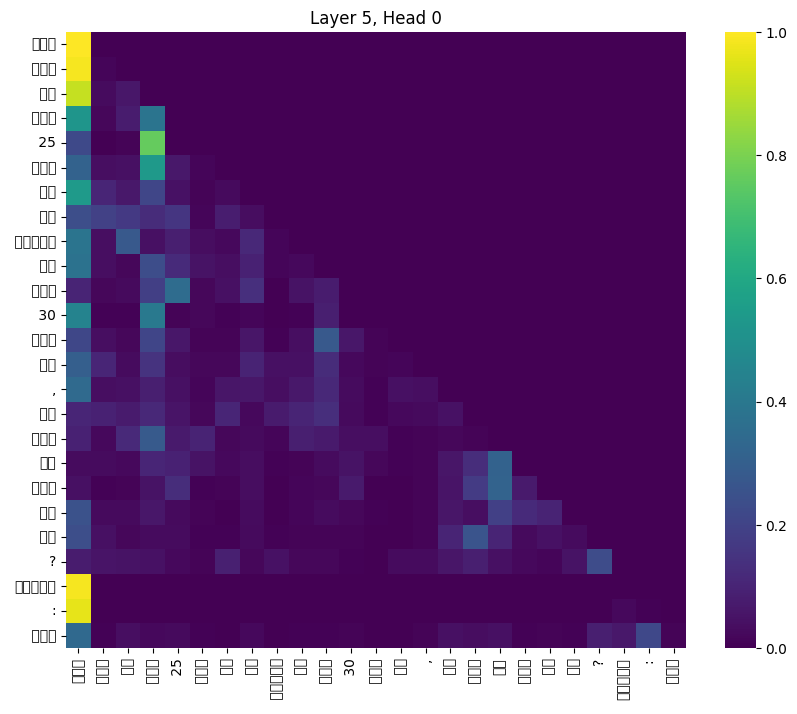

Finetuned Hindi Model Attention (Layer 5, Head 0):


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2342 (\N{DEVANAGARI LETTER DA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2367 (\N{DEVANAGARI VOWEL SIGN I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local

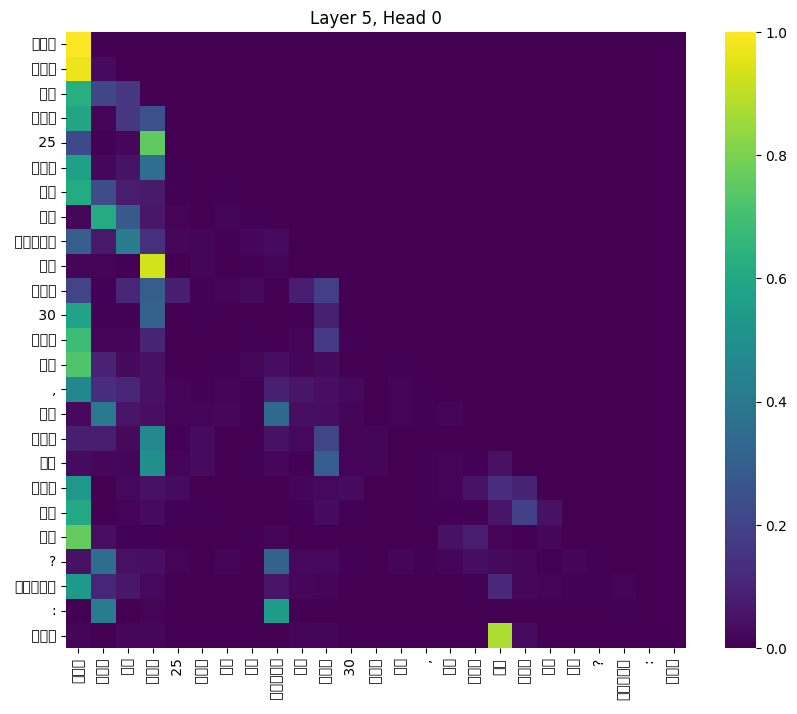

In [32]:
# Attention Visualization
def plot_attention_heatmaps(model, tokenizer, text, layer_idx=0, head_idx=0):
    model.eval()
    tokens = tokenizer.encode(text)
    idx = torch.tensor([tokens], dtype=torch.long).to(device)
    
    with torch.no_grad():
        logits, _, attention_maps = model(idx, return_attention=True)
    
    attn = attention_maps[layer_idx][0, head_idx].cpu().numpy()
    
    tok_strs = []
    for t in tokens:
        s = tokenizer.decode([t])
        tok_strs.append(s)
        
    plt.figure(figsize=(10, 8))
    sns.heatmap(attn, xticklabels=tok_strs, yticklabels=tok_strs, cmap='viridis')
    plt.title(f"Layer {layer_idx}, Head {head_idx}")
    plt.show()

try:
    sample_text = "यदि राम की आयु 25 साल है और श्याम की आयु 30 साल है, तो किसकी आयु कम है?\nउत्तर: राम"
    print("Pretrained Hindi Model Attention (Layer 5, Head 0):")
    plot_attention_heatmaps(model_h_pre, tok_h, sample_text, layer_idx=5, head_idx=0)
    print("Finetuned Hindi Model Attention (Layer 5, Head 0):")
    plot_attention_heatmaps(model_h_ft, tok_h, sample_text, layer_idx=5, head_idx=0)
except Exception as e:
    print(f"Plotting failed: {e}")


In [33]:
tokenizer_ne = TokenizerWrapper("checkpoints/pretrained/nepali/tokenizer.json")

lengths = []
with open(os.path.join(DATA_DIR, "ne/train.jsonl"), encoding='utf-8') as f:
    for line in f:
        d = json.loads(line)
        full = f"{d['prompt']}\nउत्तर: {d['answer']}"
        lengths.append(len(tokenizer_ne.encode(full)))
print("min/median/max:", min(lengths), sorted(lengths)[len(lengths)//2], max(lengths))

min/median/max: 177 444 722
